# Reading the Market's Volatility Forecast

**Implied volatility surfaces for S&P 500 and Nasdaq-100 index options**

CS 418 Project · Progress Report · Team UIC Traders

**Musa Tabally · Kaled Dahleh · Neo Uy · Anlil Iwas · Adi Latic**

12 November 2026 · Repository: github.com/Iwas1512/UnDetermined-Data-Modeling

### Summary

Our proposal asked whether option traders overestimate how much stocks will move. We now answer that question on the two
largest U.S. index option markets, SPX and NDX, using exchange data for every listed option from 24 October 2025 to 30 June 2026:
4.6 million option-days. We compute implied volatility ourselves and fit a volatility surface for every trading day
(12,246 fitted smiles). Main results so far:

- **H1 (implied > realized) holds for SPX:** 30-day implied vol exceeded the vol that followed by 1.9 points on average
  (Newey–West t ≈ 2.7). For NDX the gap (1.2 points) is not significant.
- **H3 (new):** even a fair forecast is "too high" more than half the time. Measured against that null, short-dated options look
  fairly priced. The premium sits in options more than about two weeks out.
- **H2 holds:** put skew is steeper after the market falls (rank correlation ≈ −0.65 with the past month's return).
- **SVI fits each smile** to 0.2–1.2 vol points on strikes held out of the fit, against 0.8–3.2 for a quadratic baseline.
- **Timing is not predictable yet:** logistic regression and a random forest do not beat simple baselines at predicting *when*
  options will be overpriced. We explain why and how we are changing the target.

### Team contributions

| Member | Responsible for |
|---|---|
| Musa Tabally | Data acquisition and pipeline (Sec. 3), EDA (Sec. 4), Viz 3–4 and the implied-vs-realized test, interactive viewer |
| Kaled Dahleh | Viz 1–2 (smiles and surfaces), ML 1 (SVI smile fitting and arbitrage checks) |
| Neo Uy | Viz 6 (skew after declines), ML 4 (clustering smile shapes) |
| Anlil Iwas | Viz 5 (overestimate rate against a fair-pricing null), ML 2 (logistic regression) |
| Adi Latic | ML 3 (random forest, permutation importance, error-over-time analysis) |

All analyses are code cells in the notebook `notebooks/progress_report.ipynb`; this PDF hides the code for readability.

<div class="pb"></div>

## 1. Project introduction

An option's price tells you how much the market expects the underlying to move. Inverting the Black–76 formula turns each
option price into an **implied volatility (IV)**: the annualized volatility that makes the formula match the market price.
Doing this for every strike and every expiry gives the **volatility surface**: IV as a function of moneyness
(how far the strike is from the current price) and time to expiry. The surface is the market's full forecast of the size and
shape of future moves. Its slope across strikes (*skew*) shows how much more traders pay to protect against crashes than
to bet on rallies.

We build these surfaces from scratch, for every trading day of our window, for the two largest index option markets:
**SPX** (S&P 500, root SPXW) and **NDX** (Nasdaq-100, root NDXP). Then we ask concrete, testable questions:

| # | Question | Method | Owner |
|---|---|---|---|
| Q1 | Is 30-day implied volatility **higher on average** than the volatility that actually happens over the next 30 days? | Paired test with Newey–West standard errors | Musa Tabally |
| Q2 | Can a 5-parameter curve (SVI) describe each day's smile **within the bid–ask spread**, better than a simple quadratic, on strikes it has not seen? Is the fitted surface arbitrage-free? | Non-linear least squares, strike hold-out | Kaled Dahleh |
| Q3 | Can we predict, for a given index, date and expiry, **whether the market will overestimate** the move until expiry? | Logistic regression vs. 3 baselines | Anlil Iwas |
| Q4 | Does a non-linear model do better on Q3, and which inputs matter? | Random forest, permutation importance | Adi Latic |
| Q5 | Do smile **shapes** fall into a small number of groups, and are those groups just maturity, or market regimes? | k-means on normalized smiles | Neo Uy |

**Hypotheses** (from our proposal, made precise): **H1:** implied > realized volatility on average (a *volatility risk premium*).
**H2:** put skew is steeper after the market has fallen. **H3 (new):** the commonly quoted "options overestimate the move
most of the time" is partly a statistical artifact: even a perfectly fair forecast is "too high" more than half the time.

## 2. Changes since the proposal

The feedback was *"the scope could be bigger"* and *"concrete questions could be clearer."* We changed both.

**Removed**
- The DoltHub `options` database (about 150 rows per stock per snapshot, only 3 expiries, vendor-supplied IV we could not audit, no volume).
- The "~10 single stocks, 2019–2026" universe.

**Added**
- **Exchange-grade data:** Databento's OPRA feed (the consolidated U.S. options tape): every listed SPXW and NDXP series, every expiry
  (daily expiries out to one year), the venue's closing bid/ask, cleared volume and open interest. That is **4.6 million option-days**
  (3.07 M SPX + 1.56 M NDX) from tens of millions of raw exchange records, against the roughly 1 M rows we planned.
- **We compute IV ourselves** (forward from put–call parity, Black–76 inversion) instead of trusting a vendor column.
- **Whole surfaces**, not single curves: 12,246 fitted smiles (one per index, day and expiry), with arbitrage checks.
- **Many more implied-vs-realized comparisons:** 10,135 (index, date, expiry) pairs, at horizons from 1 day to 6 months, instead of one 30-day number per stock per month.
- **Q2, Q3 and Q5 as measurable questions**, each with a baseline, and H3, which came out of the EDA.

**Trade-offs.** We now study two indexes instead of ten stocks, over 8 months instead of 7 years. So the questions moved from
"which stocks" to "which maturities, strikes and market conditions." The short window is our main limitation (Section 7).

## 3. Data and how we prepared it  *(Musa Tabally)*

**Source.** Databento `OPRA.PILLAR`, two schemas per root (SPXW, NDXP), one file per day, bought by a team member
(usage-based pricing). The raw files are licensed market data, so they are **not in the repository**. The repo contains
the scripts. Anyone with the files sets `OPRA_DATA_DIR` and runs:

```
python scripts/01_prepare_data.py   # raw -> cleaned chains, forwards, implied vols   (~2 min)
python scripts/02_fit_surfaces.py   # SVI + quadratic fits, strike hold-out test        (~12 min, 16 cores)
python scripts/03_build_features.py # constant-maturity IVs, skew, realized vol, labels
```

| raw schema | one row per | fields we use |
|---|---|---|
| `definition` | listed series per day | OSI symbol → root, expiry, call/put, strike |
| `statistics` | series × venue × statistic | closing **bid** (type 8), closing **ask** (7), cleared **volume** (6), **open interest** (9) |

On a typical day SPXW has about 17,000 listed series and about 290,000 statistics records.

**Cleaning steps** (`src/volsurf/data.py`, `forwards.py`):
1. **Duplicates.** Exchanges resend end-of-day summaries. Keep the *last* record per (series, venue, statistic). Keeping the first zeroes out volumes.
2. **Combine venues.** Best bid = highest positive bid, best ask = lowest positive ask. One venue posts 200,000.00 as "no offer"; drop that.
3. **Expired series.** Drop series expiring on or before the trade date (there is no closing quote on expiry day).
4. **Forward price and discount factor per expiry** from put–call parity, $C-P = DF\,(F-K)$: a robust straight-line fit of call-minus-put
   mid prices on strike near the money. For expiries under ~5 weeks the slope is too flat to measure, so we use the day's interest
   rate from SPX's longer expiries. NDX uses the same rate: the risk-free rate is common, and NDXP's long-dated quotes are too thin to
   pin it down on their own. This avoids having to estimate dividends.
5. **No-arbitrage filter.** An ask above $DF\cdot F$ (call) or $DF\cdot K$ (put) is impossible; mark it missing.
6. **Implied volatility.** Vectorized bisection on the Black–76 formula at the mid price. If the price is outside the arbitrage bounds, IV is missing.
7. **Open interest timing.** File *D* carries the OI at the close of day *D−1*, so we shift it back one trading day.
8. **For the smile fits** we use the out-of-the-money side (puts below the forward, calls above), drop quotes wider than
   15 vol points, and drop strikes more than 8 standard deviations out.
9. **Clock.** Time to expiry runs from the 16:15 ET closing snapshot to the 16:00 ET settlement, in calendar years (ACT/365).
   The **index level** each day is the 1-day forward times its discount factor. **Realized variance** to an expiry is the sum of squared
   daily log changes of that level, measured on the same 16:15 clock.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from matplotlib.colors import TwoSlopeNorm

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT_DIR / "src"))
from volsurf import svi

warnings.filterwarnings("ignore")
DATA = ROOT_DIR / "data" / "processed"
ROOTS = ["SPXW", "NDXP"]
NAME = {"SPXW": "SPX", "NDXP": "NDX"}
COLOR = {"SPXW": "#2a78d6", "NDXP": "#eb6834"}            # categorical slots 1 and 2
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED = "#0b0b0b", "#6b6a66"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "font.size": 9.5, "axes.titlesize": 10.5, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#b9b8b3", "axes.labelcolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "lines.linewidth": 2.0, "legend.frameon": False, "date.converter": "concise", "figure.facecolor": "white", "axes.facecolor": "white",
})
pd.set_option("display.width", 140, "display.max_columns", 20, "display.precision", 4)

cols = ["date", "expiry", "T", "cp", "K", "bid", "ask", "mid", "volume", "oi", "two_sided", "F", "k", "otm", "iv", "iv_spread"]
opts = {r: pd.read_parquet(DATA / f"options_{r}.parquet", columns=cols) for r in ROOTS}
fwd = {r: pd.read_parquet(DATA / f"forwards_{r}.parquet") for r in ROOTS}
fits = {r: pd.read_parquet(DATA / f"svi_{r}.parquet") for r in ROOTS}
daily = pd.read_parquet(DATA / "daily.parquet")
samples = pd.read_parquet(DATA / "samples.parquet")
for r in ROOTS:
    print(f"{NAME[r]}: {len(opts[r]):,} option-days, {opts[r]['date'].nunique()} trading days "
          f"({opts[r]['date'].min()} to {opts[r]['date'].max()}), {len(fits[r]):,} fitted smiles")

SPX: 3,065,818 option-days, 170 trading days (2025-10-24 to 2026-06-30), 6,672 fitted smiles
NDX: 1,557,159 option-days, 170 trading days (2025-10-24 to 2026-06-30), 5,574 fitted smiles


A few cleaned rows (one day, out-of-the-money, two-sided). `k` = ln(K/F) is log-moneyness; `iv_spread` is the bid–ask spread converted to vol units.

In [2]:
opts["SPXW"][opts["SPXW"]["date"] == opts["SPXW"]["date"].iloc[0]].query("otm and two_sided").sample(6, random_state=1)

,date,expiry,T,cp,K,bid,ask,mid,volume,oi,two_sided,F,k,otm,iv,iv_spread
6952,2025-10-24,2026-03-31,0.4328,P,6680.0,200.20,201.10,200.650,5.0,23.0,True,6888.8067,-0.0308,True,0.1670,0.0005
1048,2025-10-24,2025-11-07,0.0384,C,7075.0,0.90,1.05,0.975,45.0,537.0,True,6802.0829,0.0393,True,0.0977,0.0023
10439,2025-10-24,2025-11-28,0.0960,P,4925.0,2.15,2.30,2.225,0.0,75.0,True,6813.0739,-0.3245,True,0.4391,0.0036
15324,2025-10-24,2026-02-27,0.3453,P,6525.0,135.50,136.20,135.850,8.0,51.0,True,6872.8312,-0.0519,True,0.1771,0.0005
567,2025-10-24,2025-10-31,0.0191,P,6315.0,1.85,1.95,1.900,39.0,191.0,True,6796.9610,-0.0735,True,0.2627,0.0021
12758,2025-10-24,2025-12-31,0.1864,C,6905.0,116.80,117.40,117.100,0.0,10.0,True,6831.8005,0.0107,True,0.1284,0.0005


**How many rows survive each step:**

In [3]:
def funnel(r):
    o, f = opts[r], fits[r]
    return pd.Series({
        "series-days with expiry after the trade date": len(o),
        "with a valid two-sided closing quote": int(o["two_sided"].sum()),
        "implied vol solved (inside no-arbitrage bounds)": int(o["iv"].notna().sum()),
        "out-of-the-money side (used for smiles)": int((o["otm"] & o["iv"].notna()).sum()),
        "used in SVI fits (spread < 15 vol pts, |k|/sqrt(T) <= 8, T <= 1y)": int(f["n_quotes"].sum()),
        "fitted smiles (date x expiry)": len(f),
    })
pd.DataFrame({NAME[r]: funnel(r) for r in ROOTS}).map(lambda v: f"{v:,}")

,SPX,NDX
series-days with expiry after the trade date,"3,065,818","1,557,159"
with a valid two-sided closing quote,"2,961,929","1,449,873"
implied vol solved (inside no-arbitrage bounds),"2,834,388","1,339,105"
out-of-the-money side (used for smiles),"1,429,020","672,297"
"used in SVI fits (spread < 15 vol pts, |k|/sqrt(T) <= 8, T <= 1y)","1,423,886","671,353"
fitted smiles (date x expiry),"6,672","5,574"


**Checking the forwards.** If the forwards are right, the implied interest rate should be stable and near short-term Treasury
yields, and the 1-day forward should trace the index. Both hold: the SPX parity rate stays around 4–4.5% with no jumps, and the
forward reproduces the SPX and NDX paths, including the March 2026 sell-off and the April–June rally. (A first version estimated
NDX's rate separately and got spikes from −12% to +19%. That check is why NDX now borrows the SPX rate.)

SPX: forward method shares {'rate': 0.623, 'ols': 0.377}; median pairs used 20
NDX: forward method shares {'rate': 0.77, 'ols': 0.23}; median pairs used 20


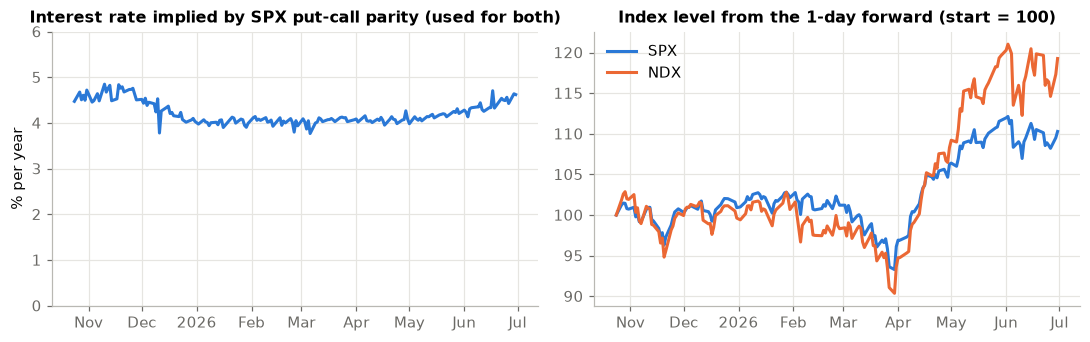

In [4]:
# Quality check on the put-call-parity forwards: the 1-day forward should move smoothly day to day,
# and the implied rate should be close to the Fed funds level (about 3.5-4% over this window).
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
rd = fwd["SPXW"].groupby("date")["r_day"].first()
ax[0].plot(pd.to_datetime(rd.index), rd * 100, color=COLOR["SPXW"])
ax[0].set_ylim(0, 6)
for r in ROOTS:
    m = fwd[r]["method"].value_counts(normalize=True)
    print(f"{NAME[r]}: forward method shares {m.round(3).to_dict()}; median pairs used {fwd[r]['n_pairs'].median():.0f}")
ax[0].set_title("Interest rate implied by SPX put-call parity (used for both)"); ax[0].set_ylabel("% per year")
for r in ROOTS:
    d = daily[daily.root == r]
    ax[1].plot(pd.to_datetime(d["date"]), d["S"] / d["S"].iloc[0] * 100, color=COLOR[r], label=NAME[r])
ax[1].set_title("Index level from the 1-day forward (start = 100)"); ax[1].legend()
plt.tight_layout(); plt.show()

<p class="caption"><b>Figure 1.</b> Checking the forwards. Left: interest rate implied by SPX put–call parity (used for both indexes). Right: index level reconstructed from the 1-day forward, rebased to 100.</p>

## 4. Exploratory data analysis  *(Musa Tabally)*

**How big the chain is, and where the trading happens.** SPX lists about 40 expiries on any day and NDX about 33. Most traded
volume (excluding same-day expiries, which have no closing quote) is in the first week.

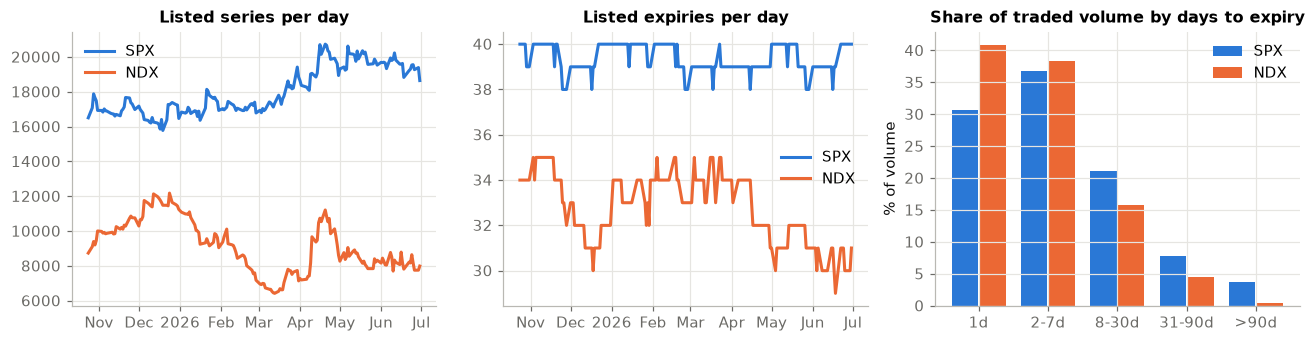

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
for r in ROOTS:
    o = opts[r]
    per = o.groupby("date").agg(series=("K", "size"), expiries=("expiry", "nunique"))
    x = pd.to_datetime(per.index)
    ax[0].plot(x, per["series"], color=COLOR[r], label=NAME[r])
    ax[1].plot(x, per["expiries"], color=COLOR[r], label=NAME[r])
    tb = pd.cut(o["T"] * 365, [0, 1.5, 7.5, 30.5, 90.5, 400], labels=["1d", "2-7d", "8-30d", "31-90d", ">90d"])
    vol = o.groupby(tb, observed=True)["volume"].sum()
    xs = np.arange(len(vol)) + (-0.2 if r == "SPXW" else 0.2)
    ax[2].bar(xs, vol / vol.sum() * 100, width=0.38, color=COLOR[r], label=NAME[r])
ax[0].set_title("Listed series per day"); ax[1].set_title("Listed expiries per day")
ax[2].set_title("Share of traded volume by days to expiry"); ax[2].set_xticks(range(5), vol.index); ax[2].set_ylabel("% of volume")
for a in ax: a.legend()
plt.tight_layout(); plt.show()

<p class="caption"><b>Figure 2.</b> Size of the option chains: listed series and expiries per day, and the share of traded volume by days to expiry.</p>

**Quote quality and shape.** Below, moneyness is *standardized*, $x = \ln(K/F)/(\sigma_{ATM}\sqrt{T})$ (roughly "how many
standard deviations away is the strike"). This puts a 1-day and a 90-day smile on the same axis.
- Spreads are tight near the money (0.1–1 vol point) and widen sharply in the wings, most of all for the shortest expiries.
- Every tenor shows the equity smile: IV rises steeply for low strikes (put protection) and flattens or turns up slightly for high strikes.

**Issues we found:**
- Same-day (0DTE) series have no closing quote, so they cannot enter a closing surface.
- Deep-OTM 1–3-day options trade at the 0.05 minimum tick, so their IV mostly reflects the tick size.
- One NDX venue's "no offer" placeholder had to be filtered.
- Open interest is stamped one day late.

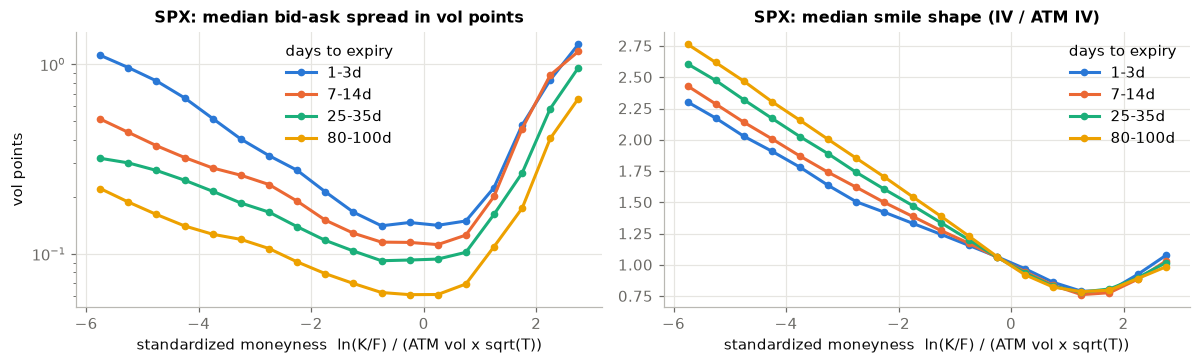

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
buckets = [(1, 3, "1-3d"), (7, 14, "7-14d"), (25, 35, "25-35d"), (80, 100, "80-100d")]
o = opts["SPXW"]; o = o[o["otm"] & o["iv"].notna()]
atm = fits["SPXW"].set_index(["date", "expiry"])["atm_iv"]
o = o.join(atm, on=["date", "expiry"])
o["x"] = o["k"] / (o["atm_iv"] * np.sqrt(o["T"]))           # standardized moneyness
for i, (lo, hi, lab) in enumerate(buckets):
    s = o[(o["T"] * 365 >= lo) & (o["T"] * 365 <= hi)]
    g = s.groupby(pd.cut(s["x"], np.arange(-6, 3.01, 0.5)), observed=True)
    mids = [iv.mid for iv in g.size().index]
    ax[0].plot(mids, g["iv_spread"].median() * 100, color=CAT[i], label=lab, marker="o", ms=4)
    ax[1].plot(mids, g["iv"].median() / g["atm_iv"].median(), color=CAT[i], label=lab, marker="o", ms=4)
ax[0].set_title("SPX: median bid-ask spread in vol points"); ax[0].set_ylabel("vol points"); ax[0].set_yscale("log")
ax[1].set_title("SPX: median smile shape (IV / ATM IV)")
for a in ax:
    a.set_xlabel("standardized moneyness  ln(K/F) / (ATM vol x sqrt(T))"); a.legend(title="days to expiry")
plt.tight_layout(); plt.show()

<p class="caption"><b>Figure 3.</b> SPX quote quality and smile shape by tenor, against standardized moneyness. Left: median bid–ask spread in vol points (log scale). Right: median IV relative to ATM IV.</p>

<div class="pb"></div>

## 5. Visualizations and hypotheses

### Viz 1 — Daily smiles with SVI and baseline fits  *(Kaled Dahleh)*
**Hypothesis:** the smile is strongly skewed (OTM puts priced at much higher IV than OTM calls), the skew is steeper for
short expiries, and a curve with 5 parameters can follow it across the whole strike range. **Why interesting:** the
skew is the price of crash protection. If a simple parametric curve fits, each day's market can be summarized by
a handful of numbers, which is what the later analyses use. The top row is a calm day, the bottom row the day with the
highest 30-day IV in our window. Grey bars are each quote's bid–ask range in vol terms. The x-range shows strikes from about −4.5 to +2.5
standard deviations.

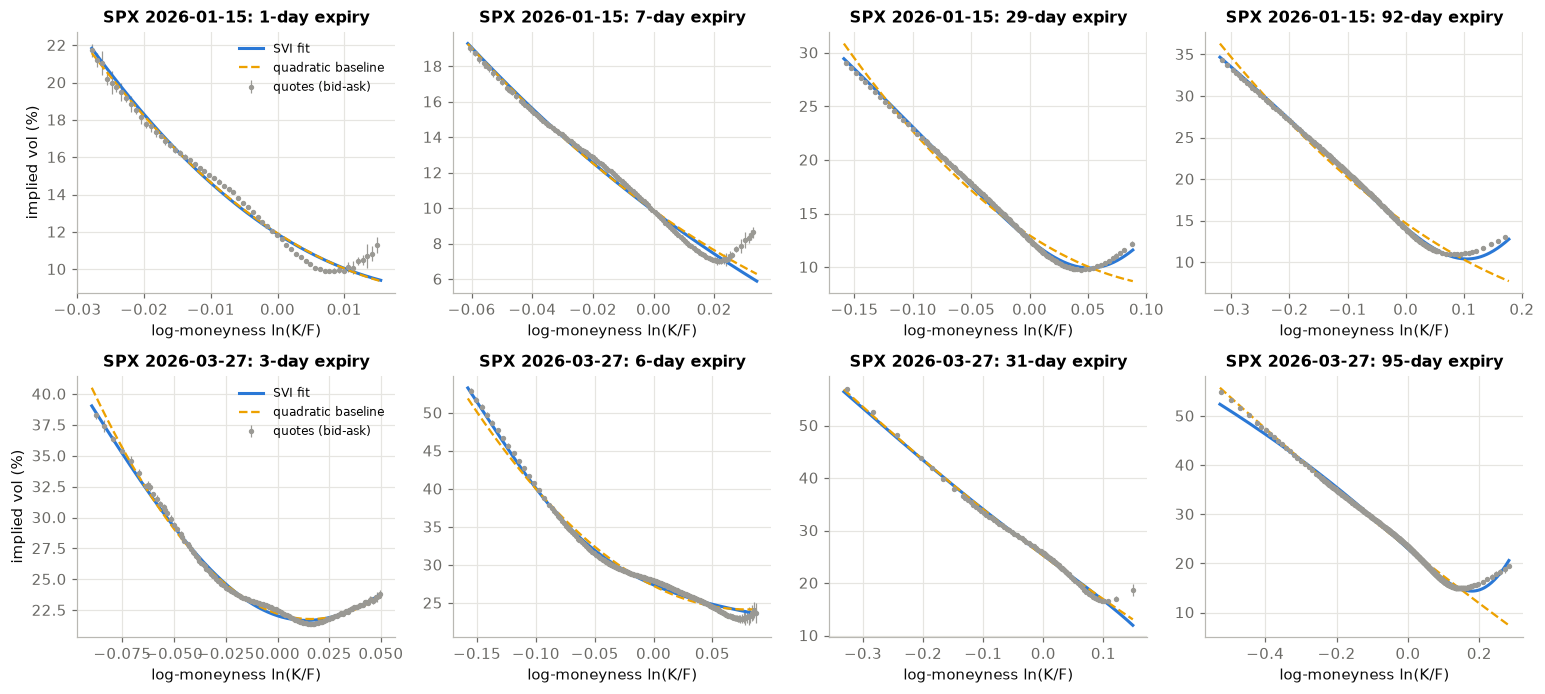

calm day: 2026-01-15; highest 30-day IV day: 2026-03-27


In [7]:
def plot_smiles(root, day, n=4, ax_row=None):
    f = fits[root][fits[root]["date"] == day].sort_values("T")
    pick = [f.iloc[np.argmin(np.abs(f["T"].to_numpy() * 365 - d))] for d in (1, 7, 30, 90)][:n]
    o = opts[root][(opts[root]["date"] == day) & opts[root]["otm"] & opts[root]["two_sided"] & opts[root]["iv"].notna()]
    for a, row in zip(ax_row, pick):
        sd = row["atm_iv"] * np.sqrt(row["T"])                    # one "standard deviation" of log-moneyness
        lo_k, hi_k = max(row["k_min"], -4.5 * sd), min(row["k_max"], 2.5 * sd)
        q = o[(o["expiry"] == row["expiry"]) & (o["k"].between(lo_k, hi_k))]
        a.errorbar(q["k"], q["iv"] * 100, yerr=q["iv_spread"] / 2 * 100, fmt="o", ms=2.5, color="#9a9994",
                   elinewidth=0.8, label="quotes (bid-ask)")
        kg = np.linspace(lo_k, hi_k, 300)
        p = row[["a", "b", "rho", "m", "s"]].to_numpy(float)
        a.plot(kg, svi.iv_svi(p, kg, row["T"]) * 100, color=COLOR[root], label="SVI fit")
        sel = q[["k", "iv", "iv_spread"]].to_numpy()
        c = svi.fit_quadratic(sel[:, 0], sel[:, 1], row["T"], sel[:, 2])
        a.plot(kg, svi.iv_quadratic(c, kg, row["T"]) * 100, color=CAT[3], lw=1.5, ls="--", label="quadratic baseline")
        a.set_title(f"{NAME[root]} {day}: {row['T']*365:.0f}-day expiry")
        a.set_xlabel("log-moneyness ln(K/F)")
    ax_row[0].set_ylabel("implied vol (%)"); ax_row[0].legend(fontsize=8)

fig, ax = plt.subplots(2, 4, figsize=(14, 6.4))
plot_smiles("SPXW", pd.Timestamp("2026-01-15").date(), ax_row=ax[0])
stress_day = daily[daily.root == "SPXW"].set_index("date")["iv30"].idxmax()
plot_smiles("SPXW", stress_day, ax_row=ax[1])
plt.tight_layout(); plt.show()
print("calm day: 2026-01-15; highest 30-day IV day:", stress_day)

<p class="caption"><b>Figure 4.</b> SPX smiles at four expiries on a calm day (top, 15 Jan 2026) and on the highest-IV day in the sample (bottom, 27 Mar 2026). Grey bars: quoted bid–ask range in vol terms; blue: SVI fit; dashed: quadratic baseline.</p>

**Reading it.**
- The hypothesis holds. The put wing is 2–5× the ATM vol, while the call side flattens and turns up just past the money (the "smirk").
- SVI tracks the curvature, including the minimum just above the forward, which the quadratic misses. ML 1 measures this.
- On the stressed day the whole surface shifts up and the short-dated smile becomes extremely steep.

### Viz 2 — The surface and its term structure  *(Kaled Dahleh)*
**Hypothesis:** in calm markets, short-dated IV is *below* long-dated IV (upward-sloping term structure). In stress the
term structure **inverts**: near-term fear is priced above long-term. **Why interesting:** the inversion is a
widely watched stress signal. We want to see whether our own surfaces reproduce it, and how often.

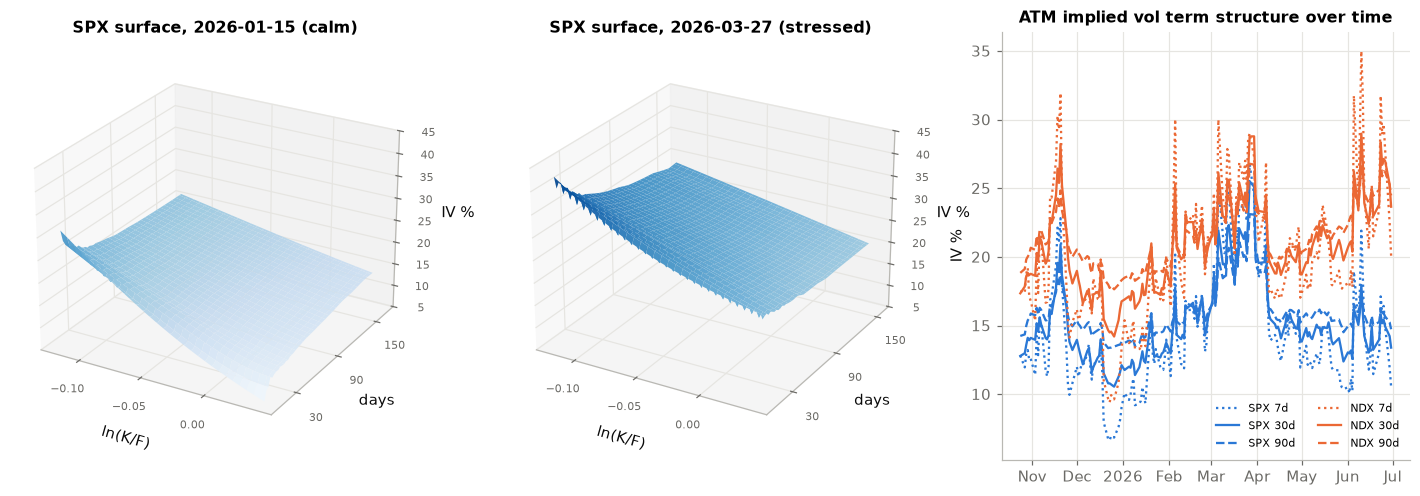

SPX: term structure inverted (7d IV > 90d IV) on 26% of days; mean IV30 on inverted days 19.0% vs 13.9% otherwise; Spearman(IV30, 7d-90d slope) = +0.85
NDX: term structure inverted (7d IV > 90d IV) on 34% of days; mean IV30 on inverted days 23.8% vs 19.3% otherwise; Spearman(IV30, 7d-90d slope) = +0.76


In [8]:
def surface_grid(root, day, x_rng=(-0.12, 0.04), t_max=0.5):
    f = fits[root][(fits[root]["date"] == day) & (fits[root]["T"] <= t_max)].sort_values("T")
    kg = np.linspace(*x_rng, 60)
    Tg = np.linspace(7 / 365, f["T"].max(), 60)
    W = np.array([svi.w_svi(p, kg) for p in f[["a", "b", "rho", "m", "s"]].to_numpy(float)])
    # linear interpolation of total variance in T at each k, as in the constant-maturity features
    Wg = np.array([np.interp(Tg, f["T"].to_numpy(), W[:, j]) for j in range(len(kg))]).T
    return kg, Tg, np.sqrt(Wg / Tg[:, None]) * 100

fig = plt.figure(figsize=(13, 4.6))
for i, (day, lab) in enumerate([(pd.Timestamp("2026-01-15").date(), "calm"), (stress_day, "stressed")]):
    kg, Tg, IV = surface_grid("SPXW", day)
    a = fig.add_subplot(1, 3, i + 1, projection="3d")
    KK, TT = np.meshgrid(kg, Tg * 365)
    a.plot_surface(KK, TT, IV, cmap="Blues", vmin=5, vmax=45, linewidth=0, antialiased=True, alpha=0.95)
    a.set_xlabel("ln(K/F)", labelpad=6); a.set_ylabel("days"); a.set_zlabel("IV %"); a.set_zlim(5, 45)
    a.set_xticks([-0.10, -0.05, 0.0]); a.set_yticks([30, 90, 150]); a.tick_params(labelsize=7)
    a.set_title(f"SPX surface, {day} ({lab})"); a.view_init(25, -60)
a = fig.add_subplot(1, 3, 3)
for r in ROOTS:
    d = daily[daily.root == r].set_index("date")
    for col, ls, lab in [("iv7", ":", "7d"), ("iv30", "-", "30d"), ("iv90", "--", "90d")]:
        a.plot(pd.to_datetime(d.index), d[col] * 100, color=COLOR[r], ls=ls, lw=1.5, label=f"{NAME[r]} {lab}")
a.set_title("ATM implied vol term structure over time"); a.set_ylabel("IV %"); a.legend(ncol=2, fontsize=7.5)
plt.tight_layout(); plt.show()
for r in ROOTS:
    d = daily[daily.root == r]
    inv = d["iv7"] > d["iv90"]
    print(f"{NAME[r]}: term structure inverted (7d IV > 90d IV) on {inv.mean():.0%} of days; "
          f"mean IV30 on inverted days {d.loc[inv, 'iv30'].mean():.1%} vs {d.loc[~inv, 'iv30'].mean():.1%} otherwise; "
          f"Spearman(IV30, 7d-90d slope) = {stats.spearmanr(d['iv30'], d['iv7'] - d['iv90'])[0]:+.2f}")

<p class="caption"><b>Figure 5.</b> Left and middle: SPX implied-vol surface (7–180 days) on a calm and a stressed day. Right: 7-, 30- and 90-day ATM implied vol over time for both indexes.</p>

**Reading it.** The two 3D panels show the same SPX surface on a calm and a stressed day: on the stressed day the whole surface
is higher and the short end is lifted above the long end. The hypothesis is supported:
- **How often:** the term structure was inverted (7-day IV above 90-day IV) on about a quarter of SPX days and a third of NDX days.
- **When:** inversions cluster in high-vol periods. SPX's average 30-day IV was 19% on inverted days against 14% otherwise.
- **Strength:** the rank correlation between the vol level and the 7-day-minus-90-day slope is about +0.8.

### Viz 3 — Implied vs. realized volatility (H1)  *(Musa Tabally)*
**Hypothesis (H1):** 30-day implied volatility is on average **above** the volatility realized over the following 30 days.
**Why interesting:** if it holds, option buyers pay a systematic premium. This is the "do traders overestimate?"
question from our proposal, now on index options. **Test:** the daily differences overlap (each 30-day window shares 29 days
with the next), so an ordinary t-test would overstate the evidence. We use **Newey–West (HAC)** standard errors with
21 lags. Grey shading marks days where implied ended up above realized; red marks days below.

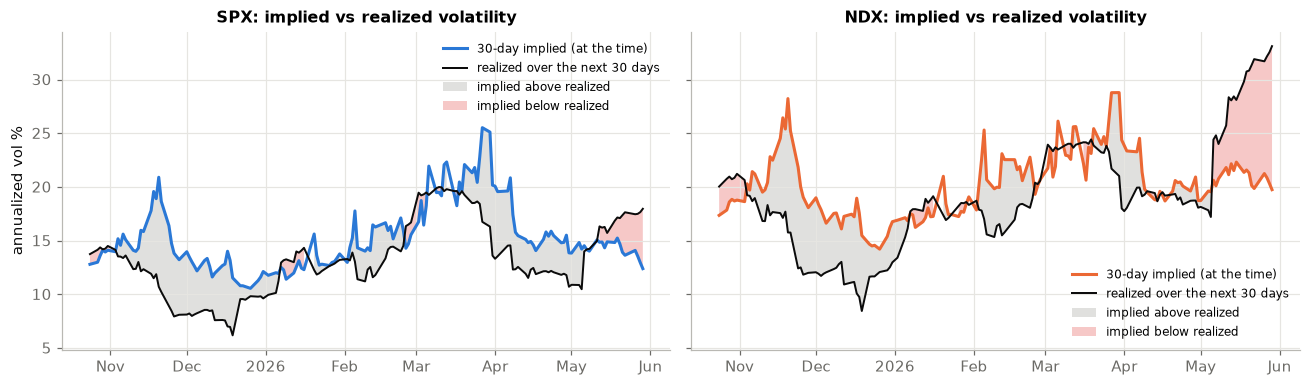

,days,mean IV30 %,mean RV30 %,share IV>RV,mean IV-RV (vol pts),NW t (vol),mean IV^2-RV^2 (x100),NW t (variance),effective obs (n/21)
index,,,,,,,,,
SPX,149,15.278,13.336,0.711,1.942,2.660,0.531,2.530,7.095
NDX,149,20.297,19.110,0.631,1.187,0.952,0.286,0.527,7.095


In [9]:
# Statistical test (Musa): is 30-day implied vol above the volatility realized over the next 30 days?
def newey_west_t(x, lags):
    x = np.asarray(x, float); n = len(x); mu = x.mean(); e = x - mu
    s = e @ e / n
    for l in range(1, lags + 1):
        s += 2 * (1 - l / (lags + 1)) * (e[l:] @ e[:-l]) / n
    se = np.sqrt(s / n)
    return mu, se, mu / se

rows = []
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for i, r in enumerate(ROOTS):
    d = daily[(daily.root == r)].dropna(subset=["rv30_fwd"]).set_index("date")
    x = pd.to_datetime(d.index)
    ax[i].plot(x, d["iv30"] * 100, color=COLOR[r], label="30-day implied (at the time)")
    ax[i].plot(x, d["rv30_fwd"] * 100, color=INK, lw=1.3, label="realized over the next 30 days")
    ax[i].fill_between(x, d["iv30"] * 100, d["rv30_fwd"] * 100, where=d["iv30"] > d["rv30_fwd"], color="#9a9994", alpha=0.3, lw=0,
                       label="implied above realized")
    ax[i].fill_between(x, d["iv30"] * 100, d["rv30_fwd"] * 100, where=d["iv30"] <= d["rv30_fwd"], color="#e34948", alpha=0.3, lw=0,
                       label="implied below realized")
    ax[i].set_title(f"{NAME[r]}: implied vs realized volatility"); ax[i].legend(fontsize=8)
    var_gap = d["iv30"] ** 2 - d["rv30_fwd"] ** 2
    mu, se, t = newey_west_t(var_gap, lags=21)
    vmu, vse, vt = newey_west_t(d["iv30"] - d["rv30_fwd"], lags=21)
    rows.append({"index": NAME[r], "days": len(d), "mean IV30 %": d["iv30"].mean() * 100,
                 "mean RV30 %": d["rv30_fwd"].mean() * 100, "share IV>RV": (d["iv30"] > d["rv30_fwd"]).mean(),
                 "mean IV-RV (vol pts)": vmu * 100, "NW t (vol)": vt,
                 "mean IV^2-RV^2 (x100)": mu * 100, "NW t (variance)": t,
                 "effective obs (n/21)": len(d) / 21})
ax[0].set_ylabel("annualized vol %")
plt.tight_layout(); plt.show()
pd.DataFrame(rows).set_index("index").round(3)

<p class="caption"><b>Figure 6.</b> 30-day implied vol against the vol realized over the following 30 days. Grey: implied ended above realized; red: below. Table: averages and Newey–West t-statistics (21 lags).</p>

**Result.**
- **SPX:** implied exceeded subsequent realized vol on about 71% of days, by **+1.9 vol points on average** (15.3% vs 13.3%).
  The Newey–West t-statistic is about 2.7 in vol terms and 2.5 in variance terms, so **H1 is supported for SPX at the 5% level.**
- **NDX:** the gap is smaller (about +1 vol point, IV above realized on 63% of days) and **not significant** (t ≈ 1.0).
- **When the premium fails:** the red areas show it fails when volatility rises *after* the options were priced. That happened
  briefly in early March 2026, and from mid-May, when NDX's realized vol jumped to 25–33% while its implied vol stayed near 20%.

Caveat: 149 overlapping days carry only about 7 independent 30-day windows, so this is evidence for one period, not a general law.

### Viz 4 — Where and when the premium shows up  *(Musa Tabally)*
**Hypothesis:** the implied-minus-realized gap is not constant. It is positive in calm months, negative in months
that run into a shock, and largest for longer tenors. **Why interesting:** this tells an option buyer *which* options
are most overpriced, which is more useful than a single average. Each cell is the mean of (ATM IV − realized vol to expiry) for
options priced in that month with that time to expiry.

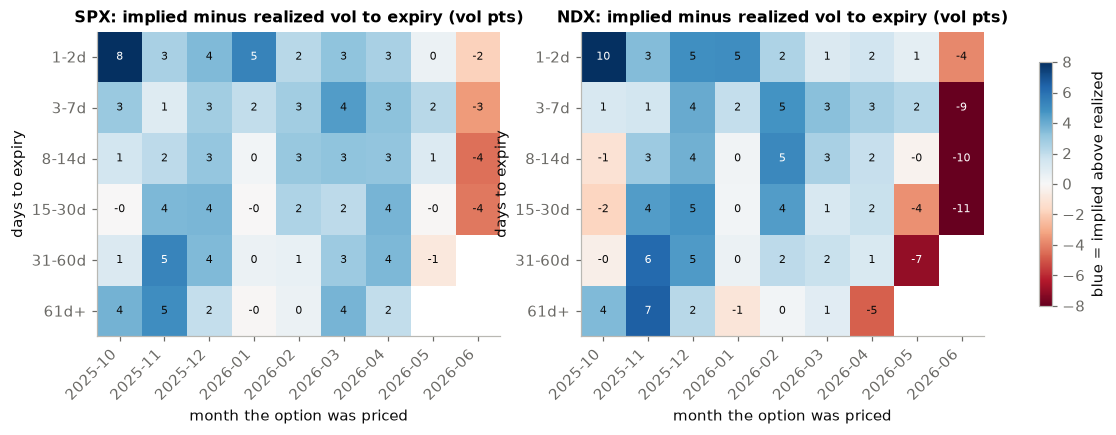

In [10]:
s = samples.copy()
s["month"] = pd.to_datetime(s["date"]).dt.to_period("M").astype(str)
s["tenor"] = pd.cut(s["days"], [0, 2.5, 7.5, 14.5, 30.5, 60.5, 200], labels=["1-2d", "3-7d", "8-14d", "15-30d", "31-60d", "61d+"])
s["gap"] = (s["atm_iv"] - s["rv_to_expiry"]) * 100
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
for i, r in enumerate(ROOTS):
    h = s[s.root == r].pivot_table(index="tenor", columns="month", values="gap", aggfunc="mean", observed=True)
    im = ax[i].imshow(h.to_numpy(), cmap="RdBu", norm=TwoSlopeNorm(0, -8, 8), aspect="auto")
    ax[i].set_xticks(range(h.shape[1]), h.columns, rotation=45, ha="right"); ax[i].set_yticks(range(h.shape[0]), h.index)
    ax[i].grid(False)
    for (a, b), v in np.ndenumerate(h.to_numpy()):
        if np.isfinite(v): ax[i].text(b, a, f"{v:.0f}", ha="center", va="center", fontsize=7, color="white" if abs(v) > 5 else INK)
    ax[i].set_title(f"{NAME[r]}: implied minus realized vol to expiry (vol pts)")
    ax[i].set_xlabel("month the option was priced"); ax[i].set_ylabel("days to expiry")
fig.colorbar(im, ax=ax, shrink=0.8, label="blue = implied above realized")
plt.show()

<p class="caption"><b>Figure 7.</b> Mean implied-minus-realized vol (vol points) by the month the option was priced and its days to expiry. Blue: implied above realized; red: below.</p>

**Reading it.**
- **Mostly positive.** The gap is positive (blue) in most cells, typically +2 to +5 vol points.
- **The March sell-off was not a failure.** Options priced in March 2026 stayed positive: IV had already jumped to about 25%,
  above what was then realized.
- **The failures came in late May and June,** when realized vol rose while IV stayed low (red): SPX −2 to −4 points,
  NDX −4 to −11. So the premium fails when a vol shock arrives *unpriced*, not just because the market is volatile.
- **Caveat on May–June:** those cells are built only from expiries up to 30 June, so they are short windows dominated by one episode.

### Viz 5 — "Options overestimate the move X% of the time": compared with what? (H3)  *(Anlil Iwas)*
**Hypothesis (H3):** a fair forecast of *variance* is "too high" more than half the time, because realized variance is
right-skewed. Over *n* days with normal returns, realized variance is $\sigma^2\chi^2_n/n$, and $P(\chi^2_n < n)$ is 68% for
*n* = 1, falling toward 50% only slowly. With fat-tailed returns the share is higher still. So the right question is not
"is the overestimate rate above 50%?" but "is it above this **null rate**?" **Why interesting:** it changes how the
headline from our proposal should be read, and it defines the target for the classifiers in ML 2 and 3. Error bars come from a
bootstrap over *trade dates*, since all options priced on one date share one future price path.

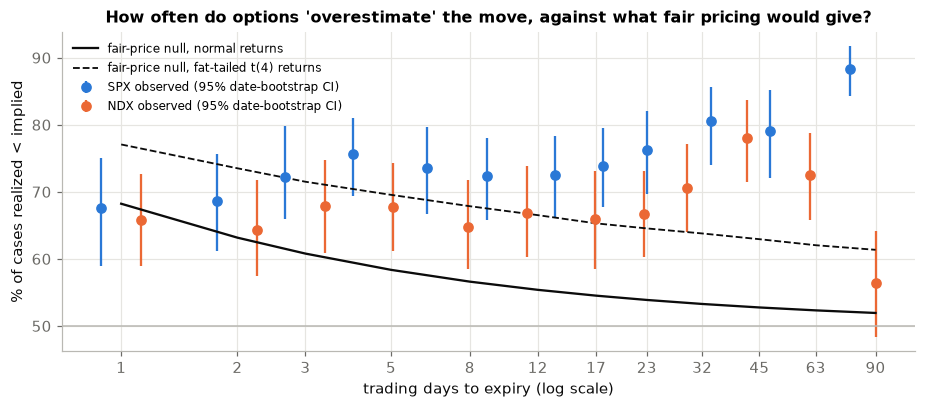

In [11]:
# How often would a FAIR forecast "overestimate"?  If daily returns have variance exactly equal to what the option
# implies, realized variance over n days is (sigma^2/n) * chi-square(n): right-skewed, so it lands BELOW its mean more
# than half the time.  The null rate is P(chi2_n < n) for normal returns (higher still with fat tails).
from scipy import stats
rng = np.random.default_rng(0)
def null_rate(n, dist="normal", sims=200_000):
    if dist == "normal":
        return stats.chi2.cdf(n, n)
    z = rng.standard_t(4, size=(sims, n)) / np.sqrt(2.0)          # unit-variance t(4)
    return np.mean((z ** 2).sum(1) < n)

s["n_days"] = s.apply(lambda r: np.busday_count(r["date"], r["expiry"]), axis=1)
edges = [0, 1, 2, 3, 5, 8, 12, 17, 23, 32, 45, 63, 130]
s["nb"] = pd.cut(s["n_days"], edges)
def date_block_ci(g, B=400):
    # bootstrap over trade dates (samples on the same date share the same future path)
    by_date = g.groupby("date")["overestimate"].agg(["sum", "size"])
    idx = rng.integers(0, len(by_date), size=(B, len(by_date)))
    sm, sz = by_date["sum"].to_numpy()[idx].sum(1), by_date["size"].to_numpy()[idx].sum(1)
    return np.percentile(sm / sz, [2.5, 97.5])

fig, ax = plt.subplots(figsize=(8.5, 3.8))
for r, off in zip(ROOTS, (-0.12, 0.12)):
    g = s[s.root == r].groupby("nb", observed=True)
    rate = g["overestimate"].mean(); n_mid = np.array([np.median(v["n_days"]) for _, v in g])
    ci = np.array([date_block_ci(v) for _, v in g])
    ax.errorbar(np.log(n_mid) + off, rate * 100, yerr=[(rate - ci[:, 0]) * 100, (ci[:, 1] - rate) * 100], fmt="o",
                ms=6, color=COLOR[r], capsize=0, lw=1.5, label=f"{NAME[r]} observed (95% date-bootstrap CI)")
ns = np.array([1, 2, 3, 5, 8, 12, 17, 23, 32, 45, 63, 90])
ax.plot(np.log(ns), [null_rate(n) * 100 for n in ns], color=INK, lw=1.5, label="fair-price null, normal returns")
ax.plot(np.log(ns), [null_rate(n, "t") * 100 for n in ns], color=INK, lw=1.2, ls="--", label="fair-price null, fat-tailed t(4) returns")
ax.axhline(50, color="#b9b8b3", lw=1)
ax.set_xticks(np.log(ns), ns); ax.set_xlabel("trading days to expiry (log scale)"); ax.set_ylabel("% of cases realized < implied")
ax.set_title("How often do options 'overestimate' the move, against what fair pricing would give?"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

<p class="caption"><b>Figure 8.</b> Share of options whose realized vol to expiry came in below implied, by days to expiry, against the fair-pricing null (solid: normal returns; dashed: fat-tailed t(4) returns). Error bars: 95% bootstrap over trade dates.</p>

**Result.**
- **Short options look fairly priced.** For 1–3-day options, the observed "overestimate" rate (64–72%) sits on or below the
  fair-price null, between the normal-returns line and the fat-tailed line.
- **Longer options look rich.** From about 2 weeks out, SPX options overestimate realized vol 72–88% of the time against a null
  of 52–56%. This is the volatility risk premium of Viz 3, and it sits mainly in the longer tenors.
- **NDX** sits closer to its null, consistent with its weaker test in Viz 3.

### Viz 6 — Put skew after the market falls (H2)  *(Neo Uy)*
**Hypothesis (H2, from the proposal):** traders pay more for downside protection after the market has fallen.
**Measure:** 30-day skew = IV at the 95% strike − IV at the 105% strike (interpolated from the SVI surfaces), against the index
return over the previous 21 trading days. **Why interesting:** if skew reacts to past returns, protection is most
expensive exactly when people want it.

SPX: Spearman(skew30, past 21-day return) = -0.64;  Spearman(skew30, iv30) = +0.73
NDX: Spearman(skew30, past 21-day return) = -0.66;  Spearman(skew30, iv30) = +0.29


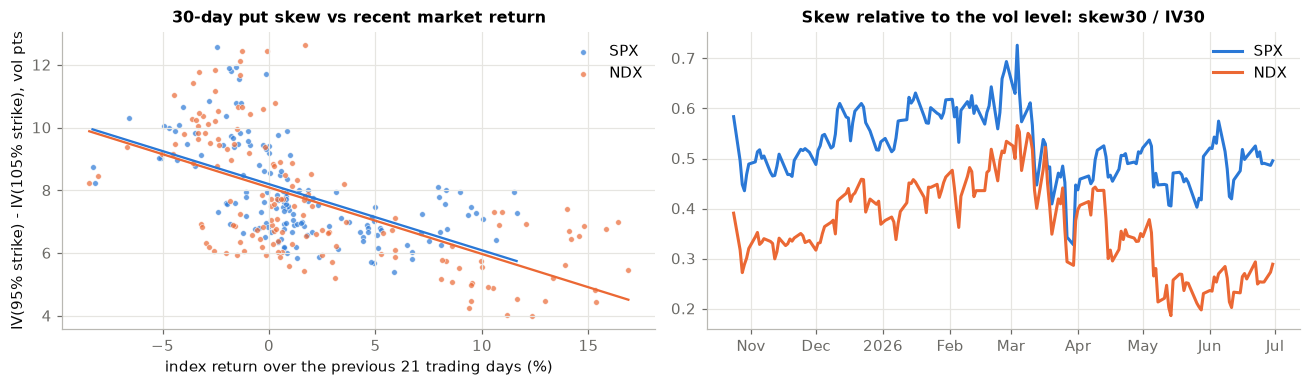

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for r in ROOTS:
    d = daily[daily.root == r].dropna(subset=["ret21"])
    ax[0].scatter(d["ret21"] * 100, d["skew30"] * 100, s=14, color=COLOR[r], alpha=0.7, edgecolor="white", lw=0.5, label=NAME[r])
    b = np.polyfit(d["ret21"] * 100, d["skew30"] * 100, 1)
    xx = np.linspace(d["ret21"].min() * 100, d["ret21"].max() * 100, 10)
    ax[0].plot(xx, np.polyval(b, xx), color=COLOR[r], lw=1.5)
    rho_ret = stats.spearmanr(d["ret21"], d["skew30"])[0]; rho_iv = stats.spearmanr(d["iv30"], d["skew30"])[0]
    print(f"{NAME[r]}: Spearman(skew30, past 21-day return) = {rho_ret:+.2f};  Spearman(skew30, iv30) = {rho_iv:+.2f}")
    d2 = daily[daily.root == r]
    ax[1].plot(pd.to_datetime(d2["date"]), d2["skew30"] / d2["iv30"], color=COLOR[r], label=NAME[r])
ax[0].set_xlabel("index return over the previous 21 trading days (%)"); ax[0].set_ylabel("IV(95% strike) - IV(105% strike), vol pts")
ax[0].set_title("30-day put skew vs recent market return"); ax[0].legend()
ax[1].set_title("Skew relative to the vol level: skew30 / IV30"); ax[1].legend()
plt.tight_layout(); plt.show()

<p class="caption"><b>Figure 9.</b> Left: 30-day put skew (IV at the 95% strike minus IV at the 105% strike) against the previous 21-day index return, with fitted lines. Right: skew relative to 30-day ATM IV over time.</p>

**Result.** H2 is supported for both indexes. The rank correlation between skew and the past-month return is
about −0.65. The fitted lines put 30-day skew about 3–4 vol points higher after a 5% drop than after a 10% rally.

The right panel adds a nuance. Measured *relative* to the vol level, skew is fairly stable. For SPX, much of the skew rise is the
whole smile moving up with volatility (Spearman correlation with IV30 is +0.73). For NDX the skew moves more on its own (+0.29).

## 6. Machine-learning analyses

### ML 1 — Smile fitting: SVI vs. quadratic baseline  *(Kaled Dahleh)*
**Model.** For each (index, date, expiry) we fit Gatheral's raw **SVI** curve to total variance $w=\sigma^2T$:
$w(k)=a+b\,[\rho(k-m)+\sqrt{(k-m)^2+s^2}]$, using bounded non-linear least squares (`scipy.optimize.least_squares`, soft-L1 loss,
4 starting points). Residuals are in IV divided by half the bid–ask spread, so wide quotes count less.
**Baseline:** a quadratic in standardized moneyness with the same weights.
**Evaluation:** hold out every third strike, re-fit both models on the rest, and score them on the held-out quotes (RMSE in vol points).

In [13]:
# ML analysis 1 (Kaled): SVI vs quadratic baseline on held-out strikes (every 3rd quote held out, model re-fit on the rest)
allf = pd.concat([fits[r].assign(index=NAME[r]) for r in ROOTS], ignore_index=True)
allf["svi_better"] = allf["cv_rmse_svi"] < allf["cv_rmse_quad"]
allf["tenor"] = pd.cut(allf["T"] * 365, [0, 2.5, 7.5, 30.5, 90.5, 400], labels=["1-2d", "3-7d", "8-30d", "31-90d", "91-365d"])
tab = allf.groupby(["index", "tenor"], observed=True).agg(
    smiles=("rmse_svi", "size"), quotes_per_smile=("n_quotes", "median"),
    holdout_err_SVI=("cv_rmse_svi", "median"), holdout_err_quadratic=("cv_rmse_quad", "median"),
    SVI_better_share=("svi_better", "mean"),
    butterfly_free=("butterfly_ok", "mean"))
for c in ["holdout_err_SVI", "holdout_err_quadratic"]:
    tab[c] = tab[c] * 100                       # vol points
tab.round(3)

smiles  quotes_per_smile  holdout_err_SVI  holdout_err_quadratic  SVI_better_share  butterfly_free
index tenor                                                                                                      
NDX   1-2d        230             228.5            1.169                  1.991             0.670           0.796
      3-7d        578             220.0            1.010                  1.579             0.690           0.894
      8-30d      2649              86.0            0.700                  1.875             0.790           0.978
      31-90d     1497              70.0            0.306                  1.142             0.866           0.996
      91-365d     620              77.0            0.234                  0.803             0.984           1.000
SPX   1-2d        230             167.5            0.871                  2.204             0.904           0.713
      3-7d        578             191.0            0.772                  2.012             0.874           0.829
      8-30d      2649             159.0            0.609                  3.158             0.887           0.989
      31-90d     2006             119.0            0.441                  3.132             0.974           0.995
      91-365d    1209             262.0            0.270                  0.995             0.953           0.993

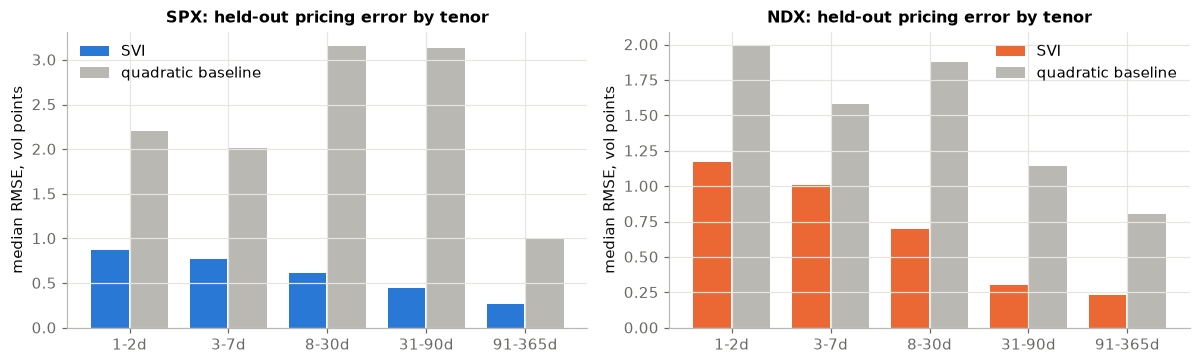

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for i, r in enumerate(ROOTS):
    f = allf[allf["index"] == NAME[r]]
    g = f.groupby("tenor", observed=True)
    x = np.arange(g.ngroups)
    ax[i].bar(x - 0.2, g["cv_rmse_svi"].median() * 100, 0.38, color=COLOR[r], label="SVI")
    ax[i].bar(x + 0.2, g["cv_rmse_quad"].median() * 100, 0.38, color="#b9b8b3", label="quadratic baseline")
    ax[i].set_xticks(x, list(g.groups.keys())); ax[i].set_title(f"{NAME[r]}: held-out pricing error by tenor")
    ax[i].set_ylabel("median RMSE, vol points"); ax[i].legend()
plt.tight_layout(); plt.show()

<p class="caption"><b>Figure 10.</b> Median held-out pricing error (RMSE, vol points) by tenor for SVI and the quadratic baseline. The table above gives the same by index and tenor, the share of smiles where SVI wins, and the share free of butterfly arbitrage.</p>

In [15]:
# Arbitrage checks on the fitted surfaces
for r in ROOTS:
    f = fits[r].sort_values(["date", "T"])
    w0 = f["atm_iv"] ** 2 * f["T"]
    same_day = f["date"].eq(f["date"].shift(-1))
    atm_cal = (w0.shift(-1) < w0)[same_day].mean()
    d = daily[daily.root == r]
    print(f"{NAME[r]}: butterfly-free smiles {f['butterfly_ok'].mean():.1%} | adjacent-expiry pairs with total variance "
          f"falling anywhere on the common strike range: {d['calendar_viol'].mean():.1%} (strict), "
          f"{d['calendar_viol_5pct'].mean():.1%} (>5% drop); at the money only: {atm_cal:.1%}")

SPX: butterfly-free smiles 96.8% | adjacent-expiry pairs with total variance falling anywhere on the common strike range: 44.2% (strict), 22.9% (>5% drop); at the money only: 0.5%
NDX: butterfly-free smiles 96.9% | adjacent-expiry pairs with total variance falling anywhere on the common strike range: 27.8% (strict), 13.1% (>5% drop); at the money only: 0.0%


**Interpretation.**
- **Accuracy.** SVI's median held-out error is 0.2–1.2 vol points depending on tenor, against 0.8–3.2 for the quadratic, and it is
  better on 67–98% of smiles. Its median error on unseen strikes is about the same as in-sample (0.5 vol points for SPX), so it is
  not overfitting. The hardest case is NDX at 1–7 days, where quotes are wider.
- **Arbitrage.** About 97% of fitted smiles are free of butterfly arbitrage (Durrleman's condition $g(k)\ge0$). The failures sit
  in the 1–7-day expiries, where wing quotes are at the minimum tick.
- **Calendar arbitrage** (total variance must grow with maturity) holds at the money (≤0.5% violations), but it fails *somewhere*
  in the wings for many adjacent daily expiries, because each expiry is fitted on its own.

Fixing that, with a surface fitted jointly across expiries (SSVI), is a next step.

### ML 2 and 3 — Predicting whether the market overestimates the move  *(Anlil Iwas: logistic regression; Adi Latic: random forest)*
**Task.** One sample per (index, trade date, expiry), with expiry up to 30 Jun 2026. **Label** = 1 if realized vol to expiry < ATM IV.

**Features (all known on the trade date):**
- maturity (log days), ATM IV, IV / trailing 21-day realized vol, 5-day / 21-day realized vol
- 5- and 21-day index returns, drawdown from the 21-day high
- term slope (IV30 − IV7), 30-day skew, ATM skew of that expiry, put/call open-interest ratio, an NDX indicator

**Baselines:**
- A: always predict the training base rate
- B: predict "overestimate" when IV exceeds trailing realized vol (a common rule of thumb)
- C: logistic regression on maturity and index only

**Evaluation 1 — chronological split.** Train on trade dates before 1 Apr 2026 *whose expiries are also before 1 Apr* (purging,
so no training label uses test-period prices). Test on trade dates from 1 Apr onward.

In [16]:
# ML analyses 2 and 3 (Anlil: logistic regression, Adi: random forest)
# Unit = one (index, trade date, expiry).  Target = 1 if realized vol to expiry < ATM implied vol ("overestimate").
s = samples.copy()
s["log_days"] = np.log(s["days"])
s["iv_over_rv21"] = s["atm_iv"] / s["rv21"]
s["rv5_over_rv21"] = s["rv5"] / s["rv21"]
s["term_slope"] = s["iv30"] - s["iv7"]
s["skew_norm"] = s["atm_skew"] * np.sqrt(s["T"])          # ATM slope in standardized units
s["is_ndx"] = (s["root"] == "NDXP").astype(int)
FEATURES = ["log_days", "atm_iv", "iv_over_rv21", "rv5_over_rv21", "ret5", "ret21", "drawdown21",
            "term_slope", "skew30", "skew_norm", "pc_oi", "is_ndx"]
s = s.dropna(subset=FEATURES + ["overestimate"])
SPLIT = pd.Timestamp("2026-04-01").date()
train = s[(s["date"] < SPLIT) & (s["expiry"] < SPLIT)]        # purge: no training label may use test-period prices
test = s[s["date"] >= SPLIT]
print(f"train: {len(train):,} samples, {train['date'].nunique()} dates ({train['date'].min()} to {train['date'].max()}), "
      f"overestimate rate {train['overestimate'].mean():.1%}")
print(f"test:  {len(test):,} samples, {test['date'].nunique()} dates ({test['date'].min()} to {test['date'].max()}), "
      f"overestimate rate {test['overestimate'].mean():.1%}")

train: 4,376 samples, 86 dates (2025-11-24 to 2026-03-30), overestimate rate 81.4%
test:  2,754 samples, 61 dates (2026-04-01 to 2026-06-29), overestimate rate 60.2%


In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, balanced_accuracy_score, roc_auc_score, brier_score_loss

Xtr, ytr, Xte, yte = train[FEATURES], train["overestimate"], test[FEATURES], test["overestimate"]
def score(name, p, thr=0.5):
    pred = (p >= thr).astype(int)
    auc = roc_auc_score(yte, p) if np.unique(p).size > 1 else 0.5
    return {"model": name, "accuracy": accuracy_score(yte, pred), "balanced acc.": balanced_accuracy_score(yte, pred),
            "ROC AUC": auc, "Brier": brier_score_loss(yte, np.clip(p, 0, 1))}

res = []
res.append(score("Baseline A: always 'overestimate' (train rate)", np.full(len(yte), ytr.mean())))
res.append(score("Baseline B: rule 'implied > trailing realized'", (test["iv_over_rv21"] > 1).astype(float).to_numpy()))
tenor_only = make_pipeline(StandardScaler(), LogisticRegression()).fit(Xtr[["log_days", "is_ndx"]], ytr)
res.append(score("Baseline C: logistic on tenor + index only", tenor_only.predict_proba(Xte[["log_days", "is_ndx"]])[:, 1]))
logit = make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=2000)).fit(Xtr, ytr)
p_logit = logit.predict_proba(Xte)[:, 1]
res.append(score("Logistic regression, all features (Anlil Iwas)", p_logit))
rf = RandomForestClassifier(n_estimators=400, min_samples_leaf=40, max_features=0.5, random_state=0, n_jobs=-1).fit(Xtr, ytr)
p_rf = rf.predict_proba(Xte)[:, 1]
res.append(score("Random forest, all features (Adi Latic)", p_rf))
pd.DataFrame(res).set_index("model").round(3)

,accuracy,balanced acc.,ROC AUC,Brier
model,,,,
Baseline A: always 'overestimate' (train rate),0.602,0.500,0.500,0.285
Baseline B: rule 'implied > trailing realized',0.336,0.329,0.329,0.664
Baseline C: logistic on tenor + index only,0.602,0.500,0.461,0.285
"Logistic regression, all features (Anlil Iwas)",0.602,0.500,0.457,0.387
"Random forest, all features (Adi Latic)",0.602,0.500,0.454,0.332


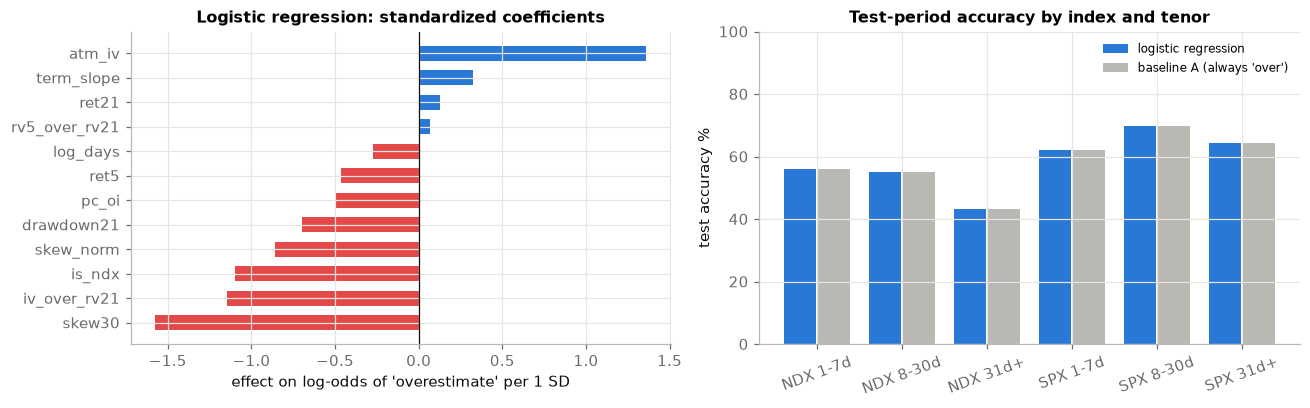

In [18]:
coef = pd.Series(logit[-1].coef_[0], index=FEATURES).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].barh(coef.index, coef.values, color=[COLOR["SPXW"] if v > 0 else "#e34948" for v in coef.values], height=0.6)
ax[0].axvline(0, color=INK, lw=0.8); ax[0].set_title("Logistic regression: standardized coefficients")
ax[0].set_xlabel("effect on log-odds of 'overestimate' per 1 SD")
t = test.assign(p=p_logit, pred=(p_logit >= 0.5).astype(int))
t["tenor"] = pd.cut(t["days"], [0, 7.5, 30.5, 200], labels=["1-7d", "8-30d", "31d+"])
acc = t.groupby(["root", "tenor"], observed=True).apply(lambda g: pd.Series({
    "model": (g["pred"] == g["overestimate"]).mean(), "baseline A": g["overestimate"].mean()}))
acc.index = [f"{NAME[a]} {b}" for a, b in acc.index]
x = np.arange(len(acc))
ax[1].bar(x - 0.2, acc["model"] * 100, 0.38, color=COLOR["SPXW"], label="logistic regression")
ax[1].bar(x + 0.2, acc["baseline A"] * 100, 0.38, color="#b9b8b3", label="baseline A (always 'over')")
ax[1].set_xticks(x, acc.index, rotation=20); ax[1].set_ylabel("test accuracy %"); ax[1].set_ylim(0, 100)
ax[1].set_title("Test-period accuracy by index and tenor"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

<p class="caption"><b>Figure 11.</b> Left: standardized logistic-regression coefficients (effect on the log-odds of "overestimate" per standard deviation). Right: test accuracy by index and tenor, logistic regression against baseline A.</p>

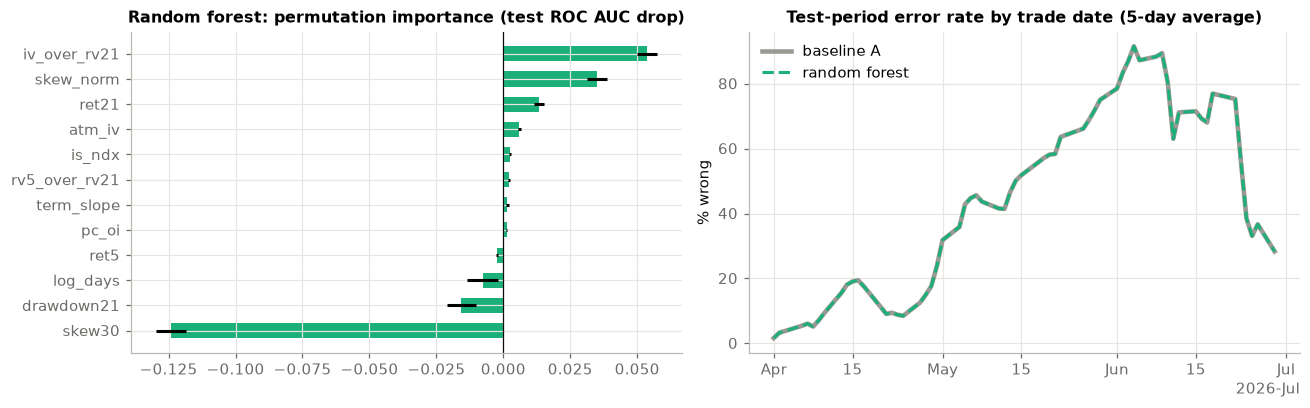

In [19]:
from sklearn.inspection import permutation_importance
pi = permutation_importance(rf, Xte, yte, scoring="roc_auc", n_repeats=10, random_state=0, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].barh(imp.index, imp.values, xerr=pi.importances_std[np.argsort(pi.importances_mean)], color=CAT[2], height=0.6)
ax[0].set_title("Random forest: permutation importance (test ROC AUC drop)"); ax[0].axvline(0, color=INK, lw=0.8)
t = test.assign(p=p_rf, err=((p_rf >= 0.5).astype(int) != test["overestimate"]).astype(int))
e = t.groupby("date").agg(rf_error=("err", "mean"), base_error=("overestimate", lambda y: 1 - y.mean()))
x = pd.to_datetime(e.index)
ax[1].plot(x, e["base_error"].rolling(5, min_periods=1).mean() * 100, color="#9a9994", lw=3, label="baseline A")
ax[1].plot(x, e["rf_error"].rolling(5, min_periods=1).mean() * 100, color=CAT[2], ls="--", label="random forest")
ax[1].set_title("Test-period error rate by trade date (5-day average)"); ax[1].set_ylabel("% wrong"); ax[1].legend()
plt.tight_layout(); plt.show()

<p class="caption"><b>Figure 12.</b> Left: random-forest permutation importance (drop in test ROC AUC when a feature is shuffled). Right: test error rate by trade date (5-day average), random forest against baseline A.</p>

**Evaluation 2 — leave-one-month-out with purging.** One split depends on one regime change, so we also test on every month in turn.

In [20]:
# Second evaluation: leave-one-month-out cross-validation with purging.  For each month, train on every sample whose
# [trade date, expiry] window does not overlap that month, and test on the month.  This uses all regimes for testing.
s["month"] = pd.to_datetime(s["date"]).dt.to_period("M")
P = {k: np.full(len(s), np.nan) for k in ["baseline A", "baseline C (tenor)", "logistic", "random forest"]}
per_month = []
for m in sorted(s["month"].unique()):
    te = (s["month"] == m).to_numpy()
    m0, m1 = m.start_time.date(), m.end_time.date()
    tr = ~te & ((s["expiry"] < m0) | (s["date"] > m1)).to_numpy()
    y = s.loc[tr, "overestimate"]
    P["baseline A"][te] = y.mean()
    P["baseline C (tenor)"][te] = make_pipeline(StandardScaler(), LogisticRegression()).fit(
        s.loc[tr, ["log_days", "is_ndx"]], y).predict_proba(s.loc[te, ["log_days", "is_ndx"]])[:, 1]
    P["logistic"][te] = make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=2000)).fit(
        s.loc[tr, FEATURES], y).predict_proba(s.loc[te, FEATURES])[:, 1]
    P["random forest"][te] = RandomForestClassifier(n_estimators=400, min_samples_leaf=40, max_features=0.5, random_state=0,
        n_jobs=-1).fit(s.loc[tr, FEATURES], y).predict_proba(s.loc[te, FEATURES])[:, 1]
    yt = s.loc[te, "overestimate"]
    per_month.append({"test month": str(m), "test samples": int(te.sum()), "train samples": int(tr.sum()),
                      "overestimate rate": yt.mean(),
                      **{f"AUC {k}": roc_auc_score(yt, P[k][te]) for k in ["baseline C (tenor)", "logistic", "random forest"]}})
pm = pd.DataFrame(per_month).set_index("test month")
y = s["overestimate"]
pooled = pd.DataFrame({k: {"accuracy": accuracy_score(y, P[k] >= 0.5), "mean per-month AUC": pm.get(f"AUC {k}", pd.Series([0.5])).mean()}
                       for k in P}).T
display(pm.round(3)); display(pooled.round(3))

,test samples,train samples,overestimate rate,AUC baseline C (tenor),AUC logistic,AUC random forest
test month,,,,,,
2025-11,277,8338,0.989,0.690,0.264,0.822
2025-12,1511,6839,0.949,0.565,0.732,0.553
2026-01,1384,6093,0.571,0.516,0.480,0.564
2026-02,1292,5909,0.784,0.405,0.656,0.544
2026-03,1397,5679,0.717,0.594,0.530,0.490
2026-04,1267,5863,0.859,0.696,0.672,0.575
2026-05,1067,6189,0.438,0.354,0.496,0.563
2026-06,420,7127,0.243,0.447,0.675,0.444


,accuracy,mean per-month AUC
baseline A,0.716,0.500
baseline C (tenor),0.716,0.533
logistic,0.657,0.563
random forest,0.637,0.569


**Interpretation (both models).**
- **Neither model beats the baselines** reliably. In the chronological split all models collapse to "always overestimate", because
  the training months had an 81% base rate and the test months 60%. Their ranking ability (AUC ≈ 0.45) is no better than chance.
- **In the monthly cross-validation,** the per-month AUC averages a little above 0.5 but swings from about 0.3 to 0.8, and no model
  beats always-predicting-the-base-rate on accuracy.
- **Both models lean most on the same inputs:** the IV / trailing-realized ratio and the skew measures.
- **Skew30 flips sign.** In the forest, permuting skew30 *improves* test AUC (large negative importance). The relation it learned
  in November–March reversed in April–June: the clearest sign of a regime change.
- **The forest predicts "overestimate" for every test sample** in the chronological split. Its error line sits exactly on the baseline's.

**Why it fails, and what that teaches us.** The label depends mainly on what the market does *after* the trade date. All options
priced on the same date share that one future path, so 7,000 samples carry roughly **8 independent months** of information. That
is too few to learn "when", and each month's base rate differs (24% to 99%). This is a real negative result, and it says *where*
predictability exists. The *cross-section* is stable: which tenors are overpriced (Viz 5). The *timing* is not predictable
with these features and 8 months. Section 8 explains how we are changing the target.

### ML 4 — Clustering smile shapes  *(Neo Uy)*
**Model.** Every fitted smile (2 days to 1 year) is sampled on a fixed grid of standardized moneyness (−2.5 to +1)
and divided by its ATM IV. That removes the vol level and the √T scaling and keeps only the **shape**. We run k-means for k = 2…7 and
choose k by silhouette score. **Baseline:** grouping by tenor bucket alone, scored with the same silhouette, plus the adjusted Rand
index (ARI) between clusters and tenor buckets.

In [21]:
# Clustering (Neo): do smile SHAPES fall into groups?  Each fitted smile is sampled on a standardized grid
# x = ln(K/F) / (ATM vol * sqrt(T)) and divided by its ATM vol, so level and tenor scaling are removed.
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
XG = np.arange(-2.5, 1.01, 0.25)
f = pd.concat([fits[r].assign(root=r) for r in ROOTS], ignore_index=True)
f = f[f["T"] * 365 >= 2]
lo, hi = XG[0] * f["atm_iv"] * np.sqrt(f["T"]), XG[-1] * f["atm_iv"] * np.sqrt(f["T"])
f = f[(f["k_min"] <= lo) & (f["k_max"] >= hi)].reset_index(drop=True)      # only where quotes cover the grid
K_ = XG[None, :] * (f["atm_iv"].to_numpy() * np.sqrt(f["T"].to_numpy()))[:, None]
P = f[["a", "b", "rho", "m", "s"]].to_numpy(float)
shape = np.array([svi.iv_svi(P[i], K_[i], f["T"].iloc[i]) for i in range(len(f))]) / f["atm_iv"].to_numpy()[:, None]
sil = {k: silhouette_score(shape, KMeans(k, n_init=10, random_state=0).fit_predict(shape), sample_size=4000, random_state=0)
       for k in range(2, 8)}
print("smiles clustered:", len(f), "| silhouette by k:", {k: round(v, 3) for k, v in sil.items()})
K_BEST = max(sil, key=sil.get)
km = KMeans(K_BEST, n_init=20, random_state=0).fit(shape)
order = np.argsort(km.cluster_centers_[:, 0])                     # cluster 1 = flattest put wing
f["cluster"] = pd.Series(km.labels_).map({c: i + 1 for i, c in enumerate(order)}).to_numpy()
f["tenor"] = pd.cut(f["T"] * 365, [0, 7.5, 30.5, 90.5, 400], labels=["2-7d", "8-30d", "31-90d", "91d+"])
base = silhouette_score(shape, f["tenor"].cat.codes, sample_size=4000, random_state=0)
print(f"chosen k = {K_BEST}; silhouette {sil[K_BEST]:.3f} vs baseline 'group by tenor bucket' {base:.3f}; "
      f"adjusted Rand vs tenor buckets {adjusted_rand_score(f['tenor'].cat.codes, f['cluster']):.3f}, "
      f"vs index {adjusted_rand_score(f['root'], f['cluster']):.3f}")

smiles clustered: 11233 | silhouette by k: {2: 0.501, 3: 0.434, 4: 0.396, 5: 0.409, 6: 0.388, 7: 0.359}


chosen k = 2; silhouette 0.501 vs baseline 'group by tenor bucket' 0.023; adjusted Rand vs tenor buckets 0.144, vs index 0.164


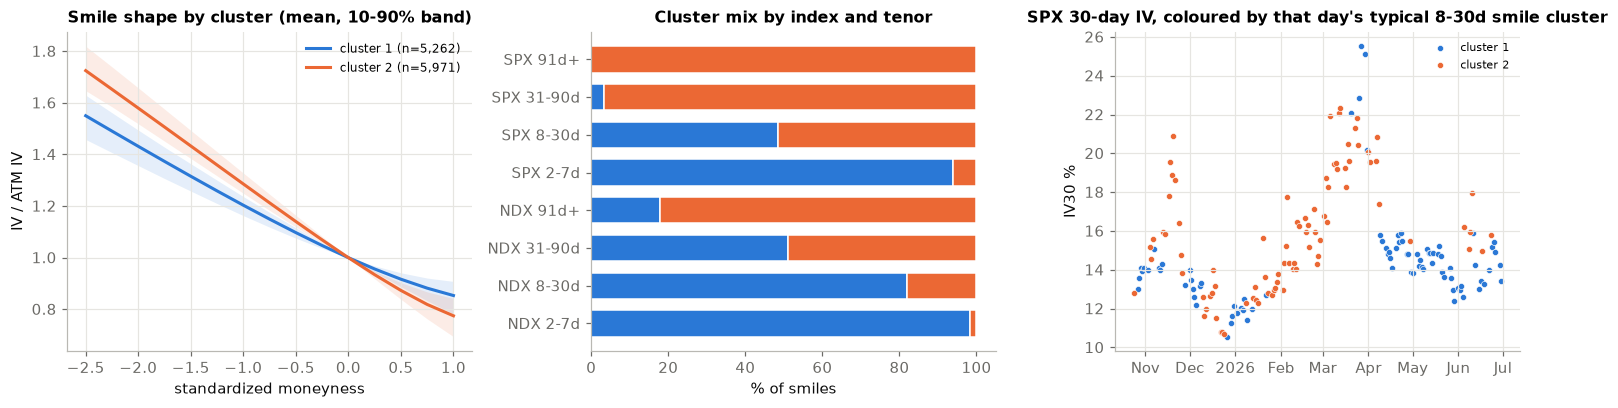

,median ATM IV,median SVI rho,share of smiles
cluster,,,
1,0.180,0.236,0.468
2,0.164,0.666,0.532


In [22]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for c in range(1, K_BEST + 1):
    m = shape[f["cluster"] == c]
    ax[0].plot(XG, m.mean(0), color=CAT[c - 1], label=f"cluster {c} (n={len(m):,})")
    ax[0].fill_between(XG, np.percentile(m, 10, 0), np.percentile(m, 90, 0), color=CAT[c - 1], alpha=0.12, lw=0)
ax[0].set_title("Smile shape by cluster (mean, 10-90% band)"); ax[0].set_xlabel("standardized moneyness")
ax[0].set_ylabel("IV / ATM IV"); ax[0].legend(fontsize=8)
comp = pd.crosstab([f["root"].map(NAME), f["tenor"]], f["cluster"], normalize="index")
left = np.zeros(len(comp))
for c in comp.columns:
    ax[1].barh(range(len(comp)), comp[c] * 100, left=left, color=CAT[c - 1], height=0.7, edgecolor="white", lw=1)
    left += comp[c].to_numpy() * 100
ax[1].set_yticks(range(len(comp)), [f"{a} {b}" for a, b in comp.index]); ax[1].set_xlabel("% of smiles")
ax[1].set_title("Cluster mix by index and tenor"); ax[1].grid(False)
m30 = f[f["tenor"] == "8-30d"].groupby(["date", "root"])["cluster"].agg(lambda x: x.mode().iloc[0]).unstack()
d = daily[daily.root == "SPXW"].set_index("date")
for c in range(1, K_BEST + 1):
    dd = m30.index[m30["SPXW"] == c]
    ax[2].scatter(pd.to_datetime(dd), d.loc[dd, "iv30"] * 100, color=CAT[c - 1], s=16, label=f"cluster {c}", edgecolor="white", lw=0.4)
ax[2].set_title("SPX 30-day IV, coloured by that day's typical 8-30d smile cluster"); ax[2].set_ylabel("IV30 %")
ax[2].legend(fontsize=7.5)
plt.tight_layout(); plt.show()
display(f.groupby("cluster")[["atm_iv", "rho"]].median().round(3).assign(share=f["cluster"].value_counts(normalize=True).sort_index().round(3))
        .rename(columns={"atm_iv": "median ATM IV", "rho": "median SVI rho", "share": "share of smiles"}))

<p class="caption"><b>Figure 13.</b> Left: mean smile shape per cluster (IV / ATM IV, shaded 10–90% band). Middle: cluster mix by index and tenor. Right: SPX 30-day IV coloured by that day's typical 8–30-day smile cluster.</p>

**Interpretation.**
- **Two shapes.** Silhouette picks *k* = 2, with much better separation (≈0.50) than grouping by tenor (≈0.02).
  - *Cluster 1:* a gentler put wing and a flatter call side.
  - *Cluster 2:* a steep, almost straight-line skew.
- **Not just maturity.** Cluster 1 dominates short-dated smiles and cluster 2 long-dated ones, but the overlap with tenor buckets
  is only moderate (ARI ≈ 0.15).
- **Partly a regime.** In the 8–30-day band the typical cluster *switches over time*: the steep shape in the November and
  February–March sell-offs, the gentler shape in calm December–January and the April–June rally. The exception is the most
  extreme days at the end of March, when IV jumped so much that the smile flattened *relative to* its ATM level.

So the shape carries market-regime information beyond maturity: a candidate feature for the next version of ML 2/3.

<div class="pb"></div>

## 7. Reflection

**Most challenging part so far.** Turning raw exchange records into trustworthy IVs. Several things looked fine but were
silently wrong until checked:
- keeping the first rather than the last duplicate record
- the one-day lag in open interest
- a venue's placeholder offer price
- getting the forward right without dividend data, which we solved with put–call parity

The second challenge is statistical: overlapping samples make naive tests and naive cross-validation far too optimistic.

**Initial insights.**
1. SPX options were priced above subsequent realized volatility (+1.9 vol points, significant). NDX's premium was smaller and not significant.
2. The premium is concentrated in longer tenors. Short-dated options look close to fairly priced once the right null is used (H3).
3. Put skew steepens after declines (H2).
4. SVI describes each day's smile to within about half a vol point on unseen strikes.

**Concrete results.** Yes: all of the above, with tests and baselines. Our predictive models (ML 2/3) do **not** beat the baselines yet,
and we can explain why.

**Biggest current problems.**
1. Only 8 months of data, so few independent outcomes for "when" questions.
2. Daily close-to-close realized vol is a noisy target for short tenors.
3. Calendar arbitrage between adjacent expiries in the fitted wings.
4. The raw data can't be shared, which complicates teamwork. Teammates work from the processed tables.

**On track?** Mostly. The data pipeline, surfaces, five-plus visualizations and four analyses are done, and the statistical test answers
our original question for SPX. A first version of the interactive page (proposal step 4) is in the repo
(`app/surface_viewer.html`: pick an index and a date to see the 3D surface, the smiles, the term structure and the 30-day
implied-vs-realized history). The prediction task needs a redesign.

**Worth continuing?** Yes. The data is far richer than our original source, two hypotheses are confirmed, and one finding (H3) changes
how the original question should be asked. The negative ML result points to a better-posed prediction problem rather than a dead end.

## 8. Next steps (plan for the next month)

| Week | Goal | Owner |
|---|---|---|
| Nov 16–22 | Replace close-to-close realized vol with **5-minute realized vol** from E-mini futures (less noisy target, especially for short tenors). Same 16:15 clock. | Musa Tabally |
| Nov 16–22 | Fit a **joint surface across expiries (SSVI)** that is calendar-arbitrage-free by construction. Compare its hold-out error with per-expiry SVI. | Kaled Dahleh |
| Nov 16–29 | Redesign ML 2/3: predict the **size** of the premium, log(realized/implied), by regression. Rank tenors by expected premium (the stable cross-sectional signal). Evaluate with purged monthly cross-validation and a block bootstrap. | Anlil Iwas, Adi Latic |
| Nov 16–29 | Cluster **whole daily surfaces** (not single smiles). PCA of daily surface changes (level / slope / curvature). Test whether the regime cluster predicts next-month realized vol. | Neo Uy |
| Nov 23–30 | **Interactive page v2:** host it on GitHub Pages; add the market quotes over each smile, the premium heatmap (Viz 4) and the smile clusters (ML 4). | All (lead: Musa Tabally) |
| Nov 30 | Final slides; Dec 7 report and cleaned derived data (SVI parameters, daily features) in the repo. | All |